<a href="https://colab.research.google.com/github/rahulraj710/AML-CID/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
# import pandas as pd

# df = pd.read_csv("/content/AML_CID_practice_sample.csv")

# df.columns = df.columns.str.strip()

# print("Dataset shape:", df.shape)

# display(df.head())

# # print(df["Label"].value_counts())

In [24]:
# from google.colab import drive
# drive.mount('/content/drive')

In [1]:
import pandas as pd
from pathlib import Path

#file_path = "/content/drive/MyDrive/cicids2017_combined.csv"
file_path = Path.home()/"Repos"/"machine-learning"/"AML-CID"/"dataset"/"cicids2017_combined.csv"

df = pd.read_csv(file_path, nrows=10000)

df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())

(10000, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [2]:

#import pandas as pd

#file_path = "/content/drive/MyDrive/cicids2017_combined.csv"

label_counts = pd.Series(dtype="int64")
total_rows = 0

# Read the dataset in groups of 50,000 rows
for chunks in pd.read_csv(file_path, chunksize=50000):

    # Clean column names
    chunks.columns = chunks.columns.str.strip()

    # Count each traffic category
    counts = chunks["Label"].value_counts()

    # Combine counts
    label_counts = label_counts.add(counts, fill_value=0)

    # Count the total rows
    total_rows += len(chunks)

# Display the results
label_counts = label_counts.astype(int)

print("Total records:", total_rows)
print("\nTraffic categories:")
print(label_counts.sort_values(ascending=False))


Total records: 2830743

Traffic categories:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
dtype: int64


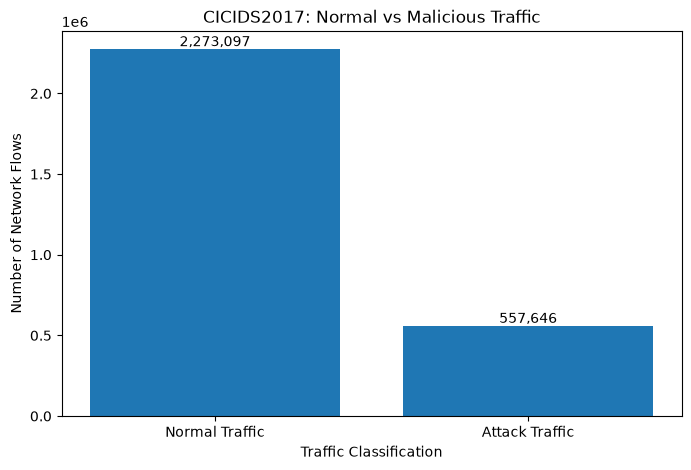

In [4]:

import matplotlib.pyplot as plt

# Combine the 14 attack categories into one group
normal = label_counts["BENIGN"]
attacks = label_counts.sum() - normal

# Create our two categories
categories = ["Normal Traffic", "Attack Traffic"]
values = [normal, attacks]

# Create the graph
plt.figure(figsize=(8, 5))
plt.bar(categories, values)

# Add a title and labels
plt.title("CICIDS2017: Normal vs Malicious Traffic")
plt.xlabel("Traffic Classification")
plt.ylabel("Number of Network Flows")

# Add record counts above the bars
for i, value in enumerate(values):
    plt.text(i, value + 20000, f"{value:,}", ha="center")

# Save the graph for our report
plt.savefig("traffic_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [5]:
#To limit each label rows count in the working sample.
sample_cap = 20000
chunksize = 50000

sampled_chunks = []

#Read the CSV in chunks so the whole file isn't loaded into memory.
for chunk in pd.read_csv(file_path, chunksize=chunksize):
    chunk.columns = chunk.columns.str.strip()

    #Drop rows without a target label.
    chunk = chunk.dropna(subset=["Label"])

    #Randomly sample each label at a rate based on its full-file count.
    sample_label = []
    for label, group in chunk.groupby("Label"):
        full_count = int(label_counts.get(label, 0))

        #Keep all rows if the class is smaller than the cap, otherwise sample approximately sample_cap rows across the full file.
        fraction = min(1.0, sample_cap / full_count) if full_count else 1.0
        sample_label.append(group.sample(frac=fraction, random_state=42))

    if sample_label:
        sampled_chunks.append(pd.concat(sample_label, ignore_index=True))

In [6]:
#To combine the sampled rows from all chunks.
data = pd.concat(sampled_chunks, ignore_index=True)

#To cap each label at sample_cap rows.
sampled_groups = []

for label, group in data.groupby("Label"):
    to_keep = min(len(group), sample_cap)
    sampled_groups.append(group.sample(n=to_keep, random_state=42))

#To combine the groups and preserve the Label column.
data = pd.concat(sampled_groups, ignore_index=True)

print("Working sample shape:", data.shape)
print(data["Label"].value_counts())

Working sample shape: (119616, 80)
Label
BENIGN                        20000
DDoS                          20000
DoS Hulk                      20000
PortScan                      20000
DoS GoldenEye                 10293
FTP-Patator                    7938
SSH-Patator                    5897
DoS slowloris                  5796
DoS Slowhttptest               5499
Bot                            1966
Web Attack � Brute Force       1507
Web Attack � XSS                652
Infiltration                     36
Web Attack � Sql Injection       21
Heartbleed                       11
Name: count, dtype: int64


In [7]:
import numpy as np
from sklearn.model_selection import train_test_split

X = data.drop(columns=["Label", "source_file"], errors="ignore")
y = data["Label"].astype(str).str.strip()

#To make sure features are numeric and replace infinite values with missing values.
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

#80/20 Training/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [31]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


#To fit and evaluate each model.
def evaluate_model(name, model):
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Macro F1:", f1_score(y_test, predictions, average="macro"))
    print(classification_report(y_test, predictions, zero_division=0))

    #For each model's multiclass Confusion Matrix
    labels = sorted(y.unique())
    fig, ax = plt.subplots(figsize=(13, 15))
    
    display = ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=labels,
        display_labels=labels,
        normalize="true",
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax        
    )

    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Predicted", labelpad=12)
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", labelrotation=60)
    display.ax_.set_title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()


Training Logistic Regression...
Accuracy: 0.9515549239257649
Macro F1: 0.7594471336690859
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.82      0.90      4000
                       Bot       0.62      0.98      0.76       393
                      DDoS       0.98      1.00      0.99      4000
             DoS GoldenEye       0.99      0.96      0.98      2059
                  DoS Hulk       0.97      0.99      0.98      4000
          DoS Slowhttptest       0.97      0.98      0.98      1100
             DoS slowloris       0.98      0.96      0.97      1159
               FTP-Patator       0.97      1.00      0.98      1588
                Heartbleed       0.67      1.00      0.80         2
              Infiltration       0.11      0.71      0.19         7
                  PortScan       0.98      0.99      0.99      4000
               SSH-Patator       0.94      0.99      0.97      1180
  Web Attack � Brute For

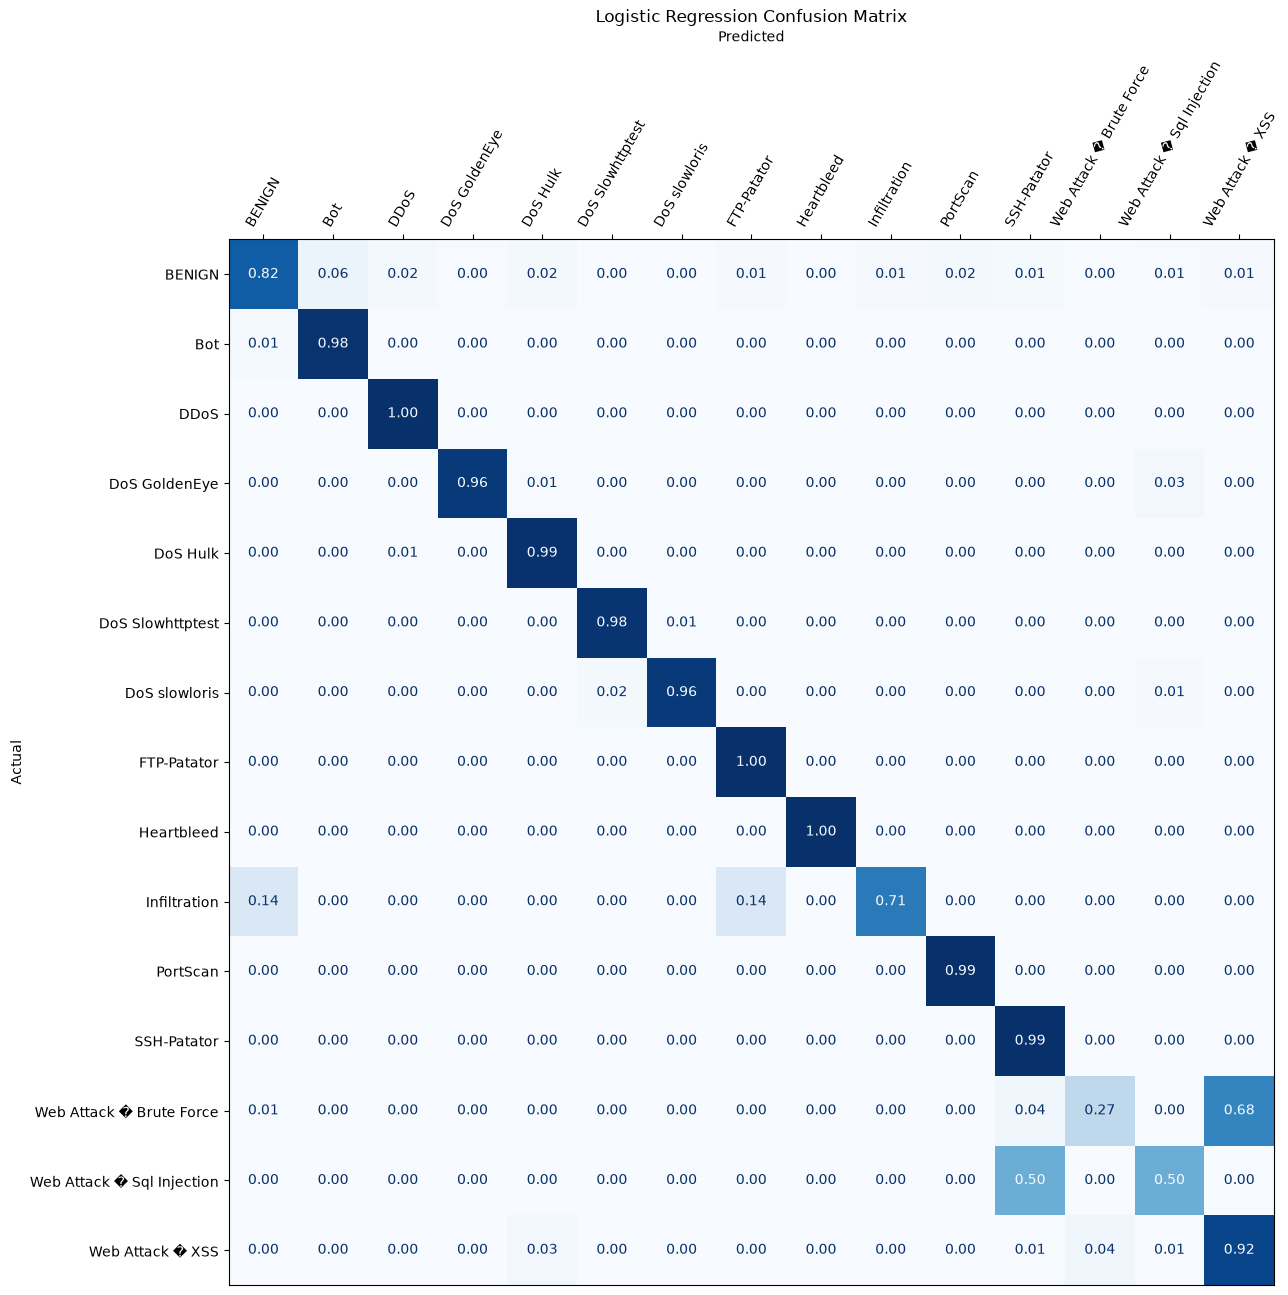

In [32]:
from sklearn.linear_model import LogisticRegression

logistic_regression = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

evaluate_model("Logistic Regression", logistic_regression)


Training Random Forest...
Accuracy: 0.9911386055843504
Macro F1: 0.8927890242820371
                            precision    recall  f1-score   support

                    BENIGN       0.99      1.00      1.00      4000
                       Bot       0.99      0.99      0.99       393
                      DDoS       1.00      1.00      1.00      4000
             DoS GoldenEye       1.00      1.00      1.00      2059
                  DoS Hulk       1.00      1.00      1.00      4000
          DoS Slowhttptest       1.00      0.99      0.99      1100
             DoS slowloris       0.99      0.99      0.99      1159
               FTP-Patator       1.00      1.00      1.00      1588
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       0.80      0.57      0.67         7
                  PortScan       1.00      1.00      1.00      4000
               SSH-Patator       1.00      1.00      1.00      1180
  Web Attack � Brute Force    

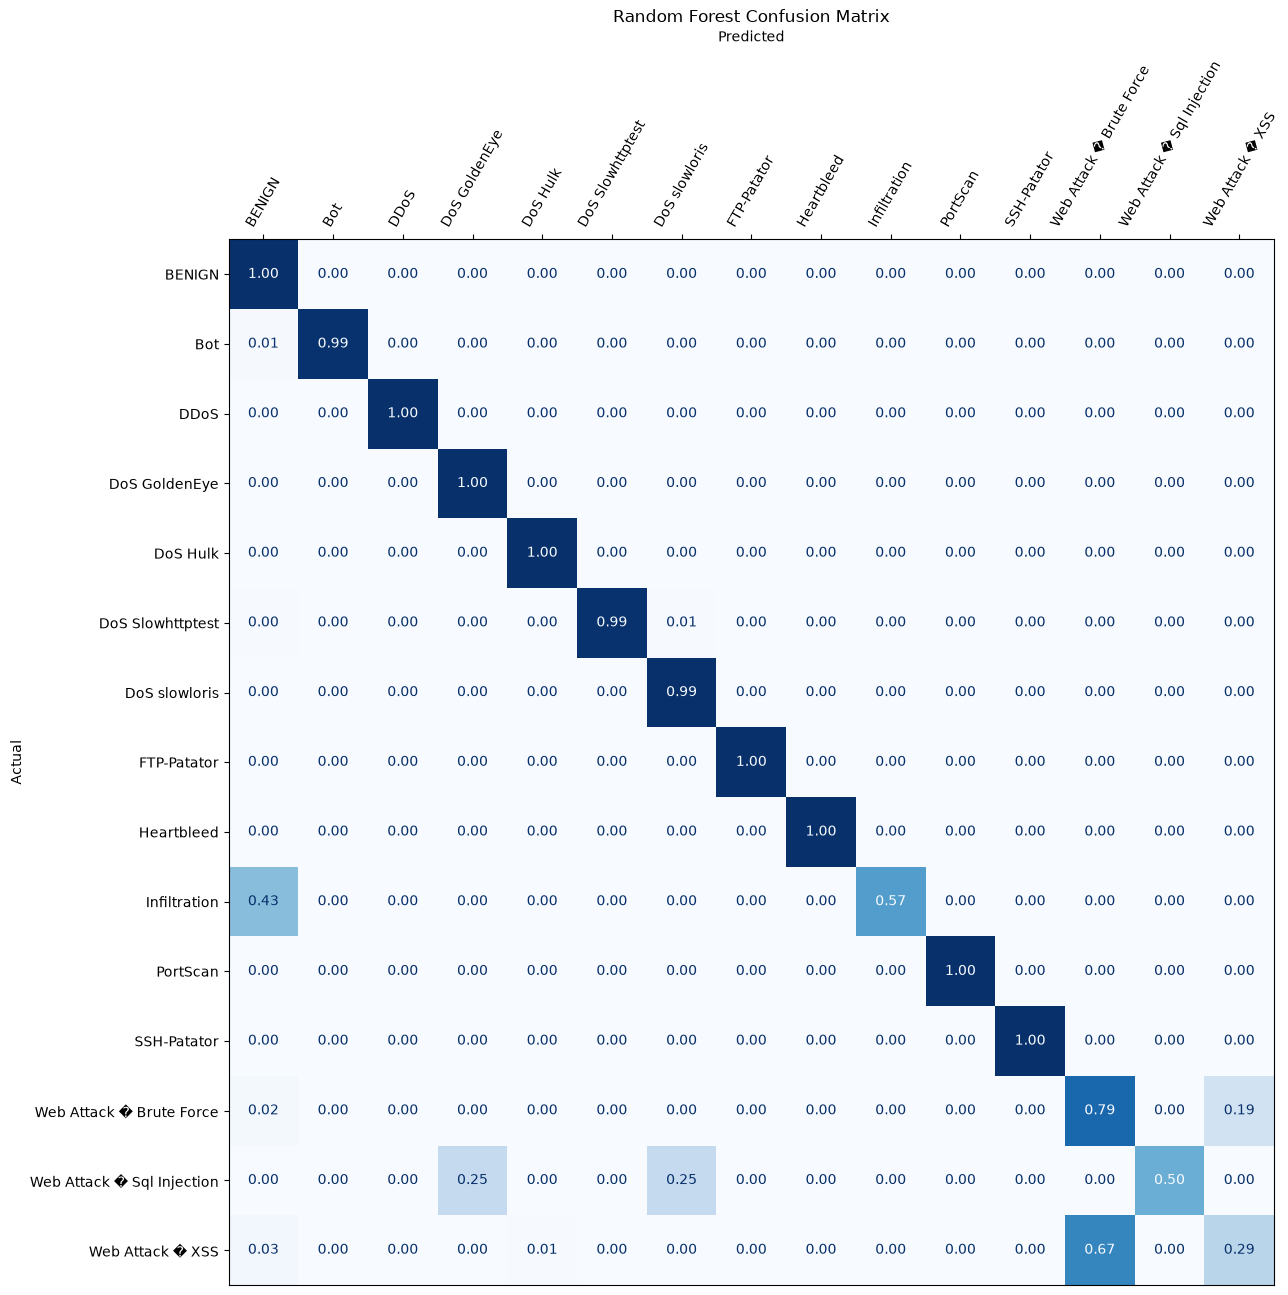

In [33]:
from sklearn.ensemble import RandomForestClassifier

random_forest = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
)

evaluate_model("Random Forest", random_forest)

In [10]:
from sklearn.svm import LinearSVC

linear_svc = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearSVC(class_weight="balanced", random_state=42, max_iter=20000)
)

evaluate_model("Linear SVM", linear_svc)


Training Linear SVM...


/jupyter/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Accuracy: 0.9551078414980773
Macro F1: 0.719009598999249
                            precision    recall  f1-score   support

                    BENIGN       0.99      0.84      0.91      4000
                       Bot       0.61      0.76      0.67       393
                      DDoS       0.97      1.00      0.99      4000
             DoS GoldenEye       0.99      0.97      0.98      2059
                  DoS Hulk       0.97      0.99      0.98      4000
          DoS Slowhttptest       0.96      0.98      0.97      1100
             DoS slowloris       0.97      0.97      0.97      1159
               FTP-Patator       0.99      0.99      0.99      1588
                Heartbleed       0.06      1.00      0.11         2
              Infiltration       0.21      0.57      0.31         7
                  PortScan       0.96      1.00      0.98      4000
               SSH-Patator       0.91      1.00      0.95      1180
  Web Attack � Brute Force       0.65      0.90      0.75 